In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [52]:
X = pd.read_csv(
    r"C:\Users\Dell\OneDrive\Desktop\ir_lab\CC GENERAL.csv"
)

print(X.head())

print("Dataset Shape:", X.shape)

  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.083333   
1                    0.000000       

In [53]:
X = X.drop('CUST_ID', axis=1)

X = X.ffill().bfill()

print("Missing Values:", X.isnull().sum().sum())

print("Dataset Shape:", X.shape)

Missing Values: 0
Dataset Shape: (8950, 17)


In [54]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (8950, 17)


In [55]:
X_normalized = normalize(X_scaled)

print("Normalized Data Shape:", X_normalized.shape)

Normalized Data Shape: (8950, 17)


In [56]:
pca = PCA(n_components=2)

X_principal = pd.DataFrame(
    pca.fit_transform(X_normalized),
    columns=['P1', 'P2']
)

print(X_principal.head())

print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

         P1        P2
0 -0.489949 -0.679976
1 -0.519099  0.544827
2  0.330633  0.268879
3 -0.481656 -0.097611
4 -0.563512 -0.482506
Explained Variance Ratio: [0.29038417 0.18386986]


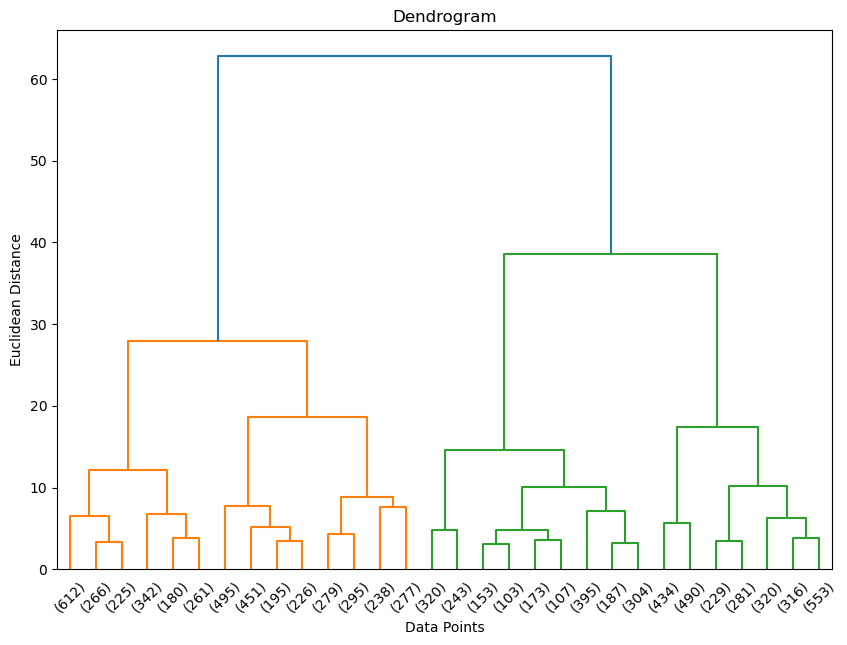

In [57]:
plt.figure(figsize=(10, 7))

plt.title("Dendrogram")

shc.dendrogram(
    shc.linkage(X_principal, method='ward'),
    truncate_mode='lastp',
    p=30
)

plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

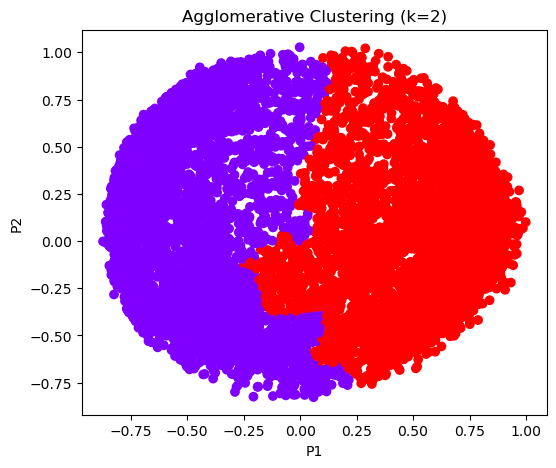

Silhouette Score for k=2: 0.4324


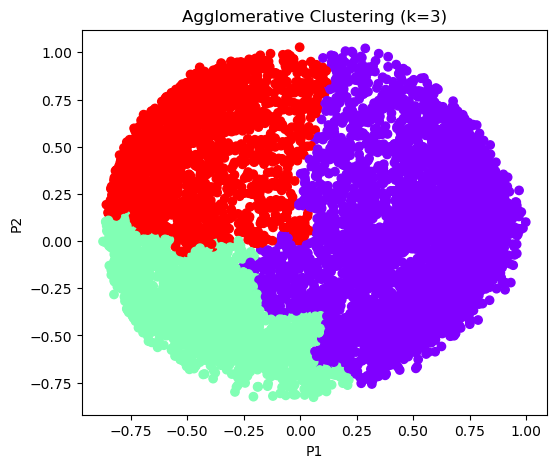

Silhouette Score for k=3: 0.4278


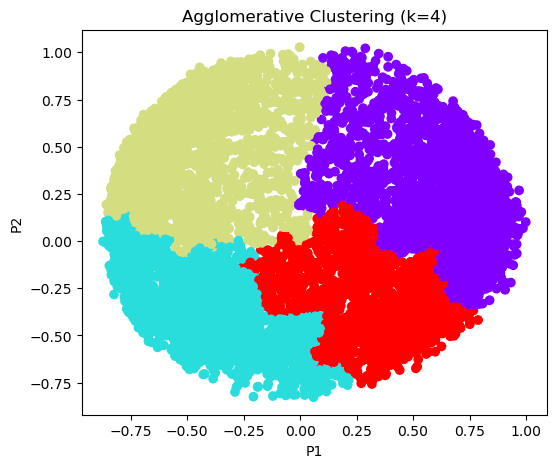

Silhouette Score for k=4: 0.3747


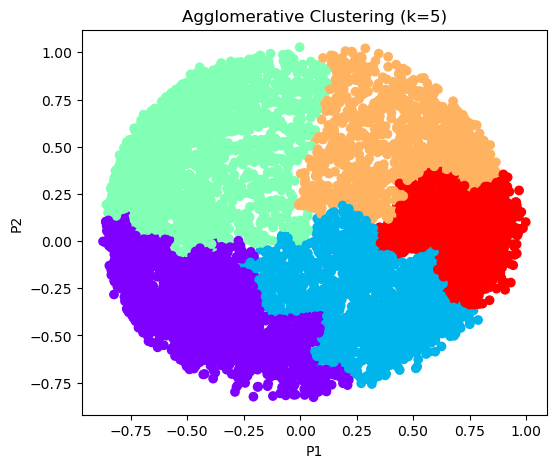

Silhouette Score for k=5: 0.3551


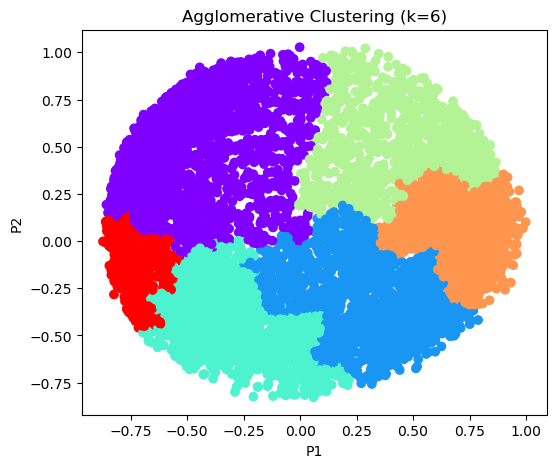

Silhouette Score for k=6: 0.3169


In [58]:
ks = [2, 3, 4, 5, 6]

scores = []

for k in ks:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_principal)

    score = silhouette_score(X_principal, labels)

    scores.append(score)

    plt.figure(figsize=(6, 5))

    plt.scatter(
        X_principal['P1'],
        X_principal['P2'],
        c=labels,
        cmap='rainbow'
    )

    plt.title(f"Agglomerative Clustering (k={k})")
    plt.xlabel("P1")
    plt.ylabel("P2")

    plt.show()

    print(f"Silhouette Score for k={k}: {score:.4f}")

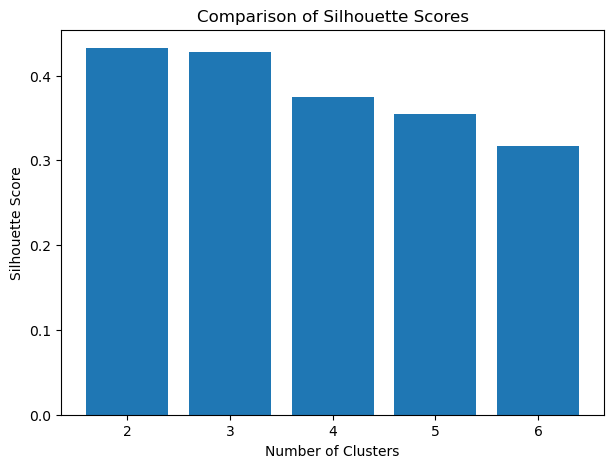

In [59]:
plt.figure(figsize=(7, 5))

plt.bar(ks, scores)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Comparison of Silhouette Scores")

plt.xticks(ks)

plt.show()

In [60]:
best_k = ks[scores.index(max(scores))]

print("Best Number of Clusters:", best_k)

print("Best Silhouette Score:", max(scores))

Best Number of Clusters: 2
Best Silhouette Score: 0.43236768272675374


In [ ]:
final_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

final_labels = final_model.fit_predict(X_principal)

X_principal['Cluster'] = final_labels

print(X_principal.head())

print("\nCluster Distribution:")

print(X_principal['Cluster'].value_counts())